# Exploratory Data Analysis (EDA) Project
**Internship Task 3 — Data Science Domain**

**Goal:** Analyze a dataset to uncover patterns and trends — using statistical summaries and visualizations, identifying correlations and key influencing factors, and presenting insights in a structured report.

**Dataset:** Diamonds (53,940 records) — price and physical/quality attributes of diamonds (carat, cut, color, clarity, dimensions).


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)


## 2. Load the Dataset

In [2]:
df = sns.load_dataset('diamonds')
print("Shape:", df.shape)
df.head()


Shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


No missing values and no duplicates to handle here — this task focuses on exploration, not cleaning.

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values: 0
Duplicate rows: 146


## 3. Statistical Summary

In [5]:
df.describe()


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [6]:
df.describe(include='category')


,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


**First observations:**
- `price` ranges from very cheap to very expensive, with a right-skewed distribution (a few very expensive diamonds pull the mean up).
- `carat` (weight) is the main size measure; `cut`, `color`, `clarity` are ordered quality grades.
- `x`, `y`, `z` are physical dimensions in mm; a few rows have 0 values, which are physically impossible and worth flagging (not full cleaning, just awareness for this EDA).


In [7]:
print("Rows with a zero dimension:", ((df['x']==0) | (df['y']==0) | (df['z']==0)).sum())


Rows with a zero dimension: 20


## 4. Univariate Analysis

### 4.1 Price Distribution

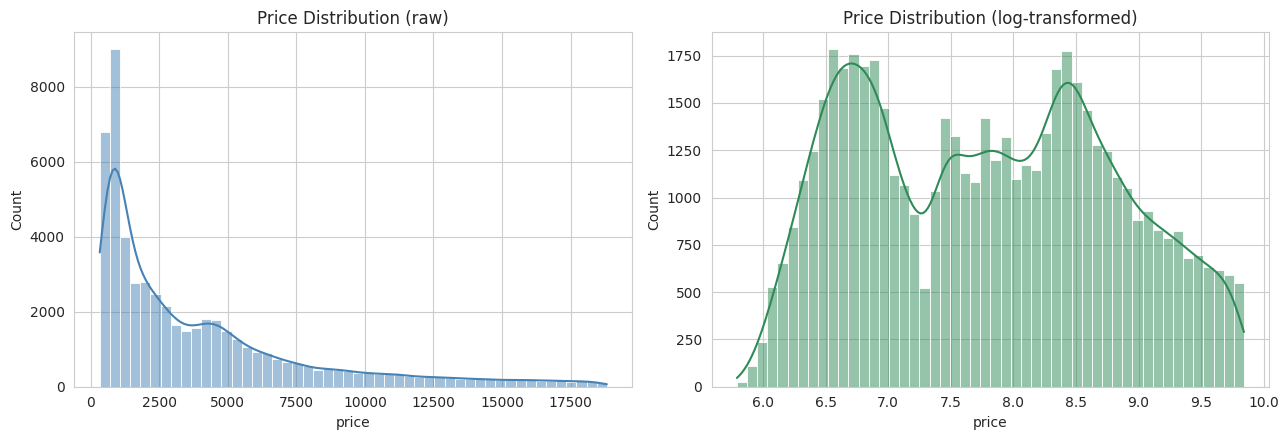

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Price Distribution (raw)')
sns.histplot(np.log1p(df['price']), bins=50, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Price Distribution (log-transformed)')
plt.tight_layout()
plt.savefig('price_distribution.png', dpi=120)
plt.show()


**Insight:** Price is heavily right-skewed (most diamonds are inexpensive, with a long tail of expensive ones). The log transform makes the shape far more symmetric, which is useful for modeling later.


### 4.2 Carat Distribution

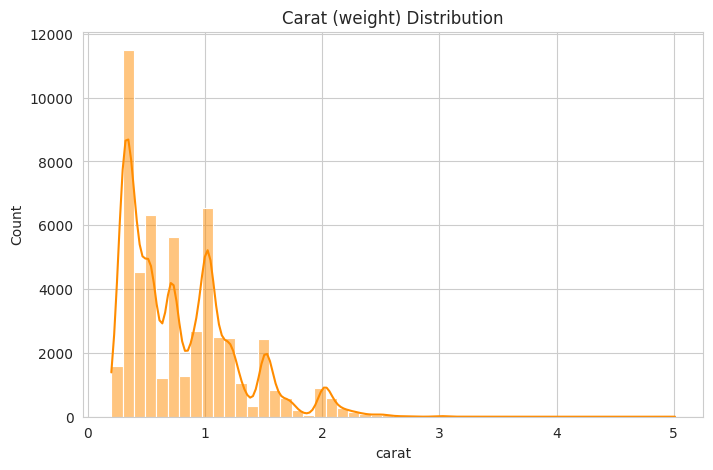

In [9]:
plt.figure()
sns.histplot(df['carat'], bins=50, kde=True, color='darkorange')
plt.title('Carat (weight) Distribution')
plt.savefig('carat_distribution.png', dpi=120)
plt.show()


### 4.3 Categorical Feature Counts

/tmp/ipykernel_93/3138922628.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cut', order=cut_order, ax=axes[0], palette='viridis')
/tmp/ipykernel_93/3138922628.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='color', order=color_order, ax=axes[1], palette='viridis')
/tmp/ipykernel_93/3138922628.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='clarity', order=[c for c in clarity_order if c in df['clarity'].unique()], ax=axes[2], palette='viridis')


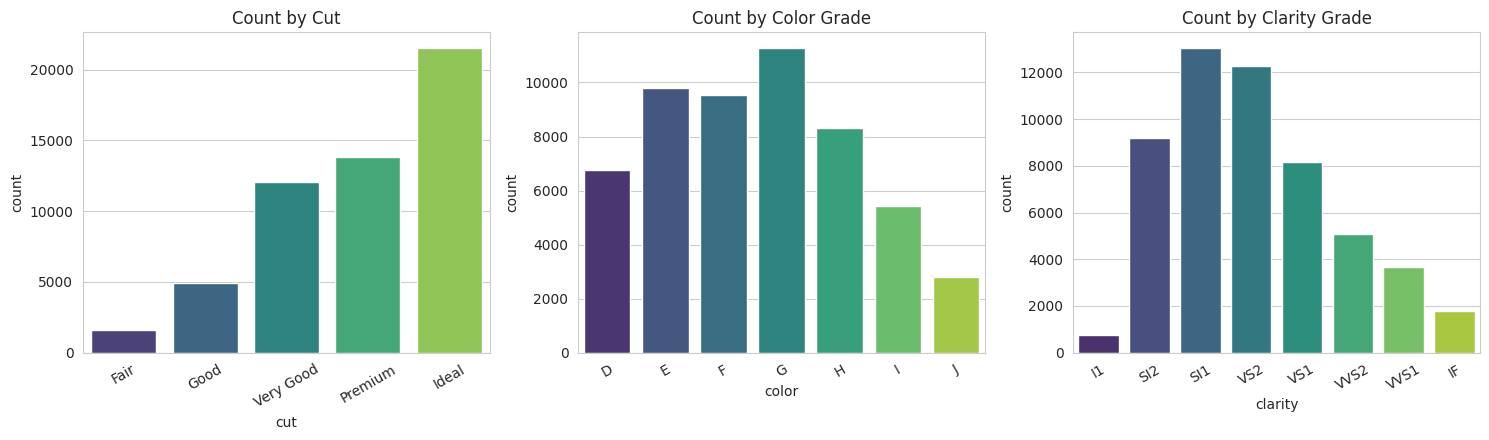

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
cut_order = ['Fair','Good','Very Good','Premium','Ideal']
color_order = sorted(df['color'].unique())
clarity_order = ['I1','SI2','SI1','VS2','VS1','VVS2','VVS1','IF']

sns.countplot(data=df, x='cut', order=cut_order, ax=axes[0], palette='viridis')
axes[0].set_title('Count by Cut')
sns.countplot(data=df, x='color', order=color_order, ax=axes[1], palette='viridis')
axes[1].set_title('Count by Color Grade')
sns.countplot(data=df, x='clarity', order=[c for c in clarity_order if c in df['clarity'].unique()], ax=axes[2], palette='viridis')
axes[2].set_title('Count by Clarity Grade')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('categorical_counts.png', dpi=120)
plt.show()


## 5. Correlation Analysis

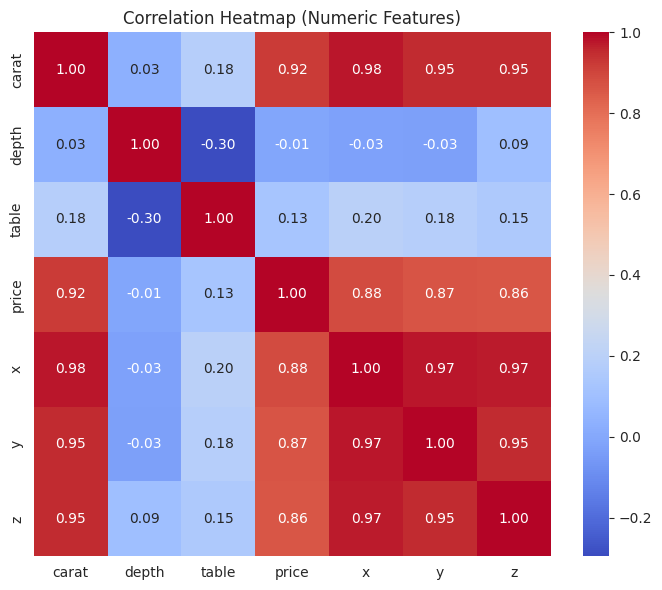

In [11]:
numeric_cols = ['carat','depth','table','price','x','y','z']
corr = df[numeric_cols].corr()

plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=120)
plt.show()


In [12]:
corr['price'].sort_values(ascending=False)


price    1.000000
carat    0.921591
x        0.884435
y        0.865421
z        0.861249
table    0.127134
depth   -0.010647
Name: price, dtype: float64

**Insight:** `carat` has by far the strongest correlation with `price` (around 0.92), followed closely by the physical dimensions `x`, `y`, `z` — which makes sense, since size and weight both scale with a diamond's dimensions. `depth` and `table` (cut proportions) have very weak correlation with price on their own.


## 6. Bivariate Analysis — Key Influencing Factors

### 6.1 Price vs Carat (the strongest relationship)

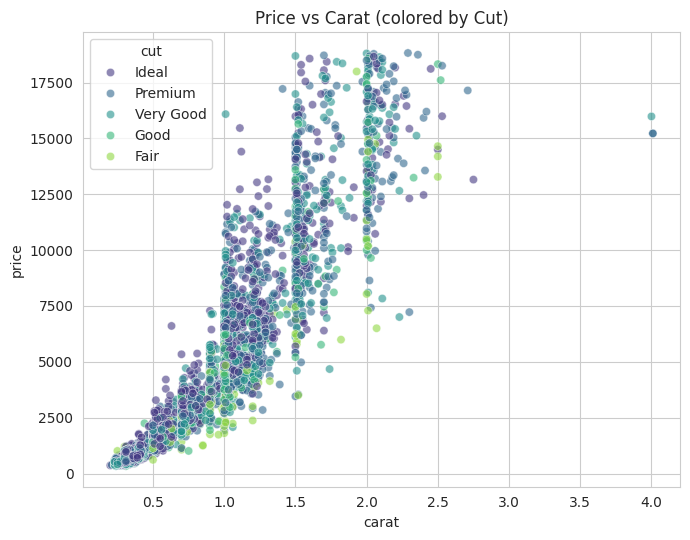

In [13]:
plt.figure(figsize=(7,5.5))
sample = df.sample(5000, random_state=42)  # sample for a readable scatter plot
sns.scatterplot(data=sample, x='carat', y='price', hue='cut', alpha=0.6, palette='viridis')
plt.title('Price vs Carat (colored by Cut)')
plt.tight_layout()
plt.savefig('price_vs_carat.png', dpi=120)
plt.show()


### 6.2 Average Price by Cut, Color, and Clarity

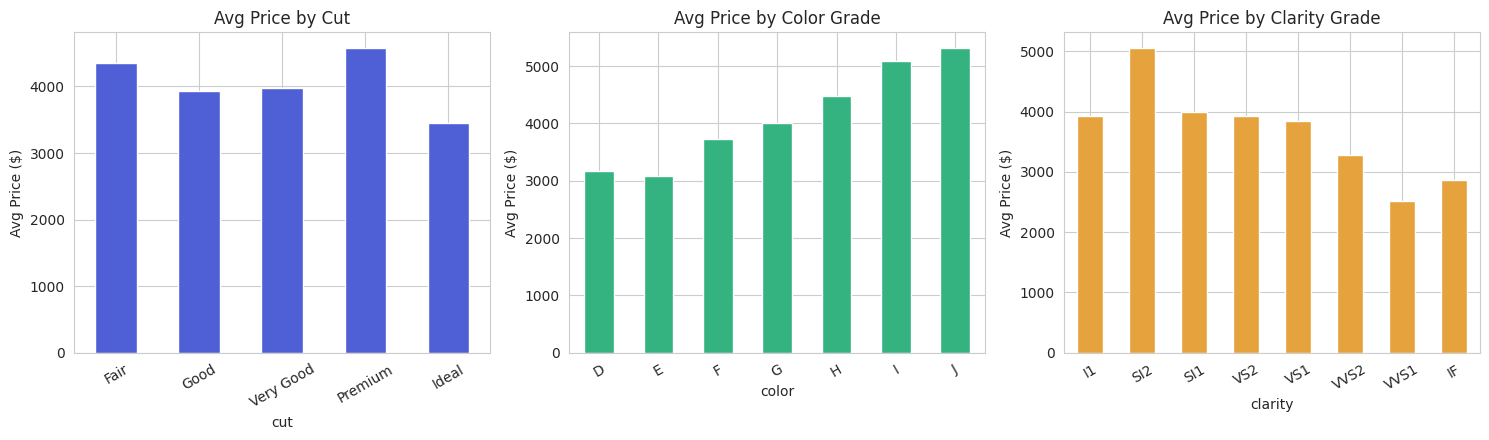

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
df.groupby('cut', observed=True)['price'].mean().reindex(cut_order).plot(kind='bar', ax=axes[0], color='#4f5fd6')
axes[0].set_title('Avg Price by Cut')
df.groupby('color', observed=True)['price'].mean().reindex(color_order).plot(kind='bar', ax=axes[1], color='#34b380')
axes[1].set_title('Avg Price by Color Grade')
df.groupby('clarity', observed=True)['price'].mean().reindex([c for c in clarity_order if c in df['clarity'].unique()]).plot(kind='bar', ax=axes[2], color='#e6a23c')
axes[2].set_title('Avg Price by Clarity Grade')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
    ax.set_ylabel('Avg Price ($)')
plt.tight_layout()
plt.savefig('avg_price_by_quality.png', dpi=120)
plt.show()


**Interesting pattern:** Average price does **not** increase monotonically with 'better' cut/color/clarity grades — e.g. 'Fair' cut diamonds can show a higher average price than 'Ideal' cut. This is a classic **confounding variable** effect: lower-grade diamonds in this dataset tend to be paired with larger carat weights, and carat dominates price far more than cut quality does. This is explored further below.


### 6.3 Explaining the confound: Carat by Cut

/tmp/ipykernel_93/1151460835.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='cut', order=cut_order, y='carat', palette='viridis')


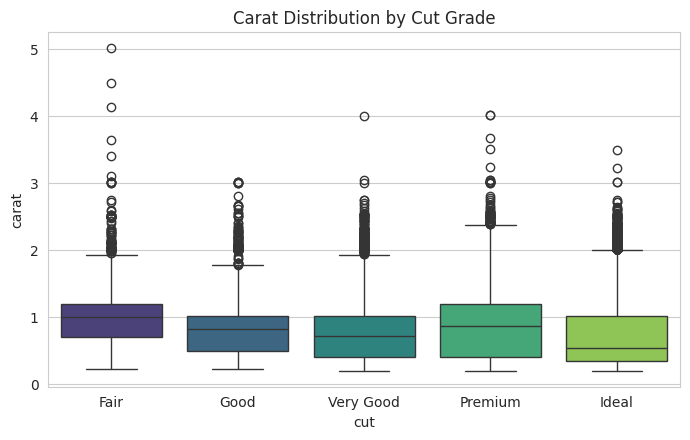

In [15]:
plt.figure(figsize=(7,4.5))
sns.boxplot(data=df, x='cut', order=cut_order, y='carat', palette='viridis')
plt.title('Carat Distribution by Cut Grade')
plt.tight_layout()
plt.savefig('carat_by_cut.png', dpi=120)
plt.show()


**Confirmed:** 'Fair' cut diamonds have a noticeably higher median carat than 'Ideal' cut diamonds in this dataset. Since carat is the dominant price driver, this explains why average price doesn't simply increase with cut quality — the two variables are confounded.


### 6.4 Price per Carat by Clarity (a fairer comparison)

/tmp/ipykernel_93/2701606405.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='clarity', order=order, y='price_per_carat', palette='viridis', showfliers=False)


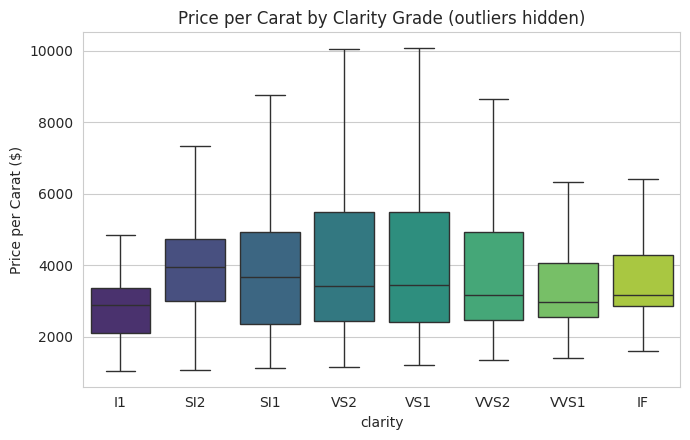

In [16]:
df['price_per_carat'] = df['price'] / df['carat']
plt.figure(figsize=(7,4.5))
order = [c for c in clarity_order if c in df['clarity'].unique()]
sns.boxplot(data=df, x='clarity', order=order, y='price_per_carat', palette='viridis', showfliers=False)
plt.title('Price per Carat by Clarity Grade (outliers hidden)')
plt.ylabel('Price per Carat ($)')
plt.tight_layout()
plt.savefig('price_per_carat_by_clarity.png', dpi=120)
plt.show()


**Insight:** Once we normalize by carat, price per carat *does* trend upward with better clarity grades — showing that clarity's effect on price is real, but was being masked by carat differences in the raw average-price comparison.


## 7. Combined Dashboard View

/tmp/ipykernel_93/446803853.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='clarity', order=order, y='price_per_carat', palette='viridis', showfliers=False, ax=axes[1,1])


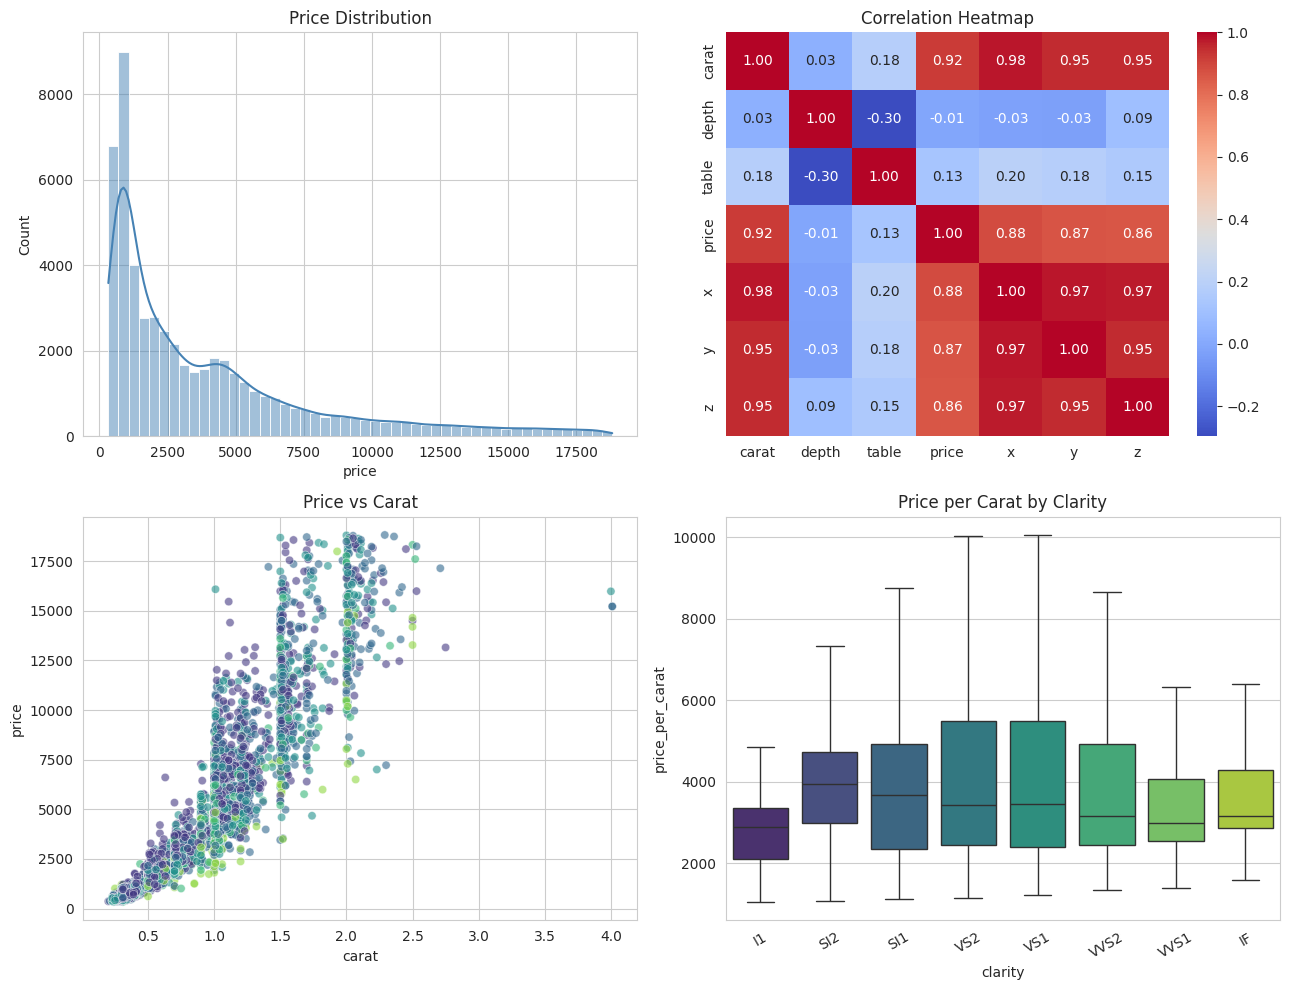

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.histplot(df['price'], bins=50, kde=True, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Price Distribution')

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0,1])
axes[0,1].set_title('Correlation Heatmap')

sns.scatterplot(data=sample, x='carat', y='price', hue='cut', alpha=0.6, palette='viridis', ax=axes[1,0], legend=False)
axes[1,0].set_title('Price vs Carat')

sns.boxplot(data=df, x='clarity', order=order, y='price_per_carat', palette='viridis', showfliers=False, ax=axes[1,1])
axes[1,1].set_title('Price per Carat by Clarity')
axes[1,1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('dashboard_summary.png', dpi=120)
plt.show()


## 8. Key Insights (Structured Summary)

1. **Carat is the dominant driver of price** — it correlates with price at about 0.92, far more strongly than any quality grade (cut, color, clarity) on its own.
2. **Price is right-skewed** — most diamonds are modestly priced, with a long tail of expensive outliers; a log transform makes the distribution much more symmetric.
3. **Raw average price by cut is misleading** — 'Fair' cut diamonds can show a higher average price than 'Ideal' cut diamonds, purely because they tend to be larger (a confounding variable), not because lower cut quality is worth more.
4. **Clarity's real effect shows up once you normalize by carat** — price per carat trends upward with better clarity grades, confirming clarity does add value once size is held constant.
5. **Physical dimensions (x, y, z) are highly correlated with carat and each other** (as expected, since they all describe the same physical size), so they carry largely redundant information for price prediction.

## 9. Conclusion

This EDA shows that price in this dataset is overwhelmingly explained by diamond size (carat), while quality grades (cut, color, clarity) have smaller, often confounded effects that only become visible when size is controlled for (e.g. using price-per-carat). This is a good example of why correlation alone can mislead without checking for confounding variables — a key analytical thinking skill this task was meant to develop.
